# Initial data exploration

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Support running from either the project root or the notebook directory.
project_root = Path.cwd()
if not (project_root / "data" / "wsh_pitches.csv").exists():
    project_root = project_root.parent

pitches = pd.read_csv(project_root / "data" / "wsh_pitches.csv")
pitches.head()

,batter_id,pitcher_id,throw_side,bat_side,is_fb,is_in_zone,is_swing,is_miss
0,1,200,R,R,0,0,1,1
1,1,30,L,R,1,0,1,0
2,1,27,R,R,0,0,0,0
3,1,91,L,R,0,1,1,0
4,1,83,R,R,0,0,0,0


### Data missingness checks and confirming binary columns

In [13]:
total_pitches = len(pitches)
print(f"Total pitches: {total_pitches:,}")

rate_columns = ["is_fb", "is_in_zone", "is_swing", "is_miss"]
display(pitches.isna().sum().rename("missing_count").to_frame())
display(pitches[rate_columns].agg(["min", "max"]))

assert not pitches.isna().any().any(), "Review missing values before computing fractions."
assert pitches[rate_columns].isin([0, 1]).all().all()
assert pitches[["throw_side", "bat_side"]].isin(["L", "R"]).all().all()
assert (pitches["is_miss"] <= pitches["is_swing"]).all()

Total pitches: 94,495


,missing_count
batter_id,0
pitcher_id,0
throw_side,0
bat_side,0
is_fb,0
is_in_zone,0
is_swing,0
is_miss,0


,is_fb,is_in_zone,is_swing,is_miss
min,0,0,0,0
max,1,1,1,1


### Splits by bat/throw side

In [14]:
throw_counts = pitches["throw_side"].value_counts().sort_index()
throw_summary = pd.DataFrame({
    "pitch_count": throw_counts,
    "fraction": throw_counts / total_pitches,
})
throw_summary

,pitch_count,fraction
throw_side,,
L,20345,0.215302
R,74150,0.784698


In [15]:
bat_counts = pitches["bat_side"].value_counts().sort_index()
bat_summary = pd.DataFrame({
    "pitch_count": bat_counts,
    "fraction": bat_counts / total_pitches,
})
bat_summary

,pitch_count,fraction
bat_side,,
L,34126,0.361141
R,60369,0.638859


In [16]:
handedness_counts = pitches.groupby(["throw_side", "bat_side"]).size()
handedness_summary = pd.DataFrame({
    "pitch_count": handedness_counts,
    "fraction": handedness_counts / total_pitches,
})
handedness_summary

pitch_count  fraction
throw_side bat_side                       
L          L                4591  0.048585
           R               15754  0.166718
R          L               29535  0.312556
           R               44615  0.472141

### Pitch fractions, overall and by platoon

`contact_rate` = (swings − misses) / swings, computed within each group. It is undefined (NaN) for groups with no swings. The other fractions use all pitches as the denominator.

In [17]:
rate_names = {
    "is_fb": "fastball_fraction",
    "is_in_zone": "in_zone_fraction",
    "is_swing": "swing_fraction",
    "is_miss": "swing_and_miss_fraction",
}
overall_rates = pitches[rate_columns].mean().rename(index=rate_names)
swing_count = pitches["is_swing"].sum()
miss_count = pitches["is_miss"].sum()
overall_rates["contact_rate"] = (
    (swing_count - miss_count) / swing_count if swing_count > 0 else float("nan")
)
overall_rates.to_frame("fraction")

,fraction
fastball_fraction,0.539129
in_zone_fraction,0.489931
swing_fraction,0.523541
swing_and_miss_fraction,0.207408
contact_rate,0.603837


In [18]:
rates_by_throw = pitches.groupby("throw_side")[rate_columns].mean().rename(columns=rate_names)
rates_by_throw.insert(0, "pitch_count", throw_counts)

swing_miss_counts = pitches.groupby("throw_side")[["is_swing", "is_miss"]].sum()
rates_by_throw["contact_rate"] = (
    (swing_miss_counts["is_swing"] - swing_miss_counts["is_miss"])
    / swing_miss_counts["is_swing"].where(swing_miss_counts["is_swing"] > 0)
)
rates_by_throw

,pitch_count,fastball_fraction,in_zone_fraction,swing_fraction,swing_and_miss_fraction,contact_rate
throw_side,,,,,,
L,20345,0.495896,0.482576,0.421283,0.136495,0.676000
R,74150,0.550991,0.491949,0.551598,0.226864,0.588714


In [19]:
rates_by_bat = pitches.groupby("bat_side")[rate_columns].mean().rename(columns=rate_names)
rates_by_bat.insert(0, "pitch_count", bat_counts)

swing_miss_counts = pitches.groupby("bat_side")[["is_swing", "is_miss"]].sum()
rates_by_bat["contact_rate"] = (
    (swing_miss_counts["is_swing"] - swing_miss_counts["is_miss"])
    / swing_miss_counts["is_swing"].where(swing_miss_counts["is_swing"] > 0)
)
rates_by_bat

,pitch_count,fastball_fraction,in_zone_fraction,swing_fraction,swing_and_miss_fraction,contact_rate
bat_side,,,,,,
L,34126,0.545625,0.491356,0.486345,0.097287,0.799964
R,60369,0.535457,0.489125,0.544568,0.269658,0.504821


In [20]:
rates_by_matchup = (
    pitches.groupby(["throw_side", "bat_side"])[rate_columns]
    .mean()
    .rename(columns=rate_names)
)
rates_by_matchup.insert(0, "pitch_count", handedness_counts)

swing_miss_counts = pitches.groupby(["throw_side", "bat_side"])[["is_swing", "is_miss"]].sum()
rates_by_matchup["contact_rate"] = (
    (swing_miss_counts["is_swing"] - swing_miss_counts["is_miss"])
    / swing_miss_counts["is_swing"].where(swing_miss_counts["is_swing"] > 0)
)
rates_by_matchup

pitch_count  fastball_fraction  in_zone_fraction  \
throw_side bat_side                                                     
L          L                4591           0.492267          0.478545   
           R               15754           0.496953          0.483750   
R          L               29535           0.553919          0.493347   
           R               44615           0.549053          0.491023   

                     swing_fraction  swing_and_miss_fraction  contact_rate  
throw_side bat_side                                                         
L          L               0.630146                 0.380091      0.396820  
           R               0.360416                 0.065507      0.818246  
R          L               0.463992                 0.053327      0.885070  
           R               0.609593                 0.341746      0.439387

### Pitches per pitcher, batter, and pitcher–batter pair

In [21]:
pitcher_counts = pitches.groupby("pitcher_id").size().rename("pitch_count")
batter_counts = pitches.groupby("batter_id").size().rename("pitch_count")
pair_counts = pitches.groupby(["pitcher_id", "batter_id"]).size().rename("pitch_count")

print(f"Unique pitchers: {len(pitcher_counts):,}")
print(f"Unique batters: {len(batter_counts):,}")
print(f"Unique pitcher–batter pairs: {len(pair_counts):,}")

pd.DataFrame({
    "pitcher": pitcher_counts.describe(),
    "batter": batter_counts.describe(),
    "pitcher_batter_pair": pair_counts.describe(),
})

Unique pitchers: 200
Unique batters: 200
Unique pitcher–batter pairs: 31,498


,pitcher,batter,pitcher_batter_pair
count,200.000000,200.000000,31498.000000
mean,472.475000,472.475000,3.000032
std,37.270563,284.569037,1.982357
min,404.000000,49.000000,1.000000
25%,447.000000,215.500000,1.000000
50%,464.000000,437.000000,3.000000
75%,486.250000,717.250000,4.000000
max,576.000000,1005.000000,16.000000


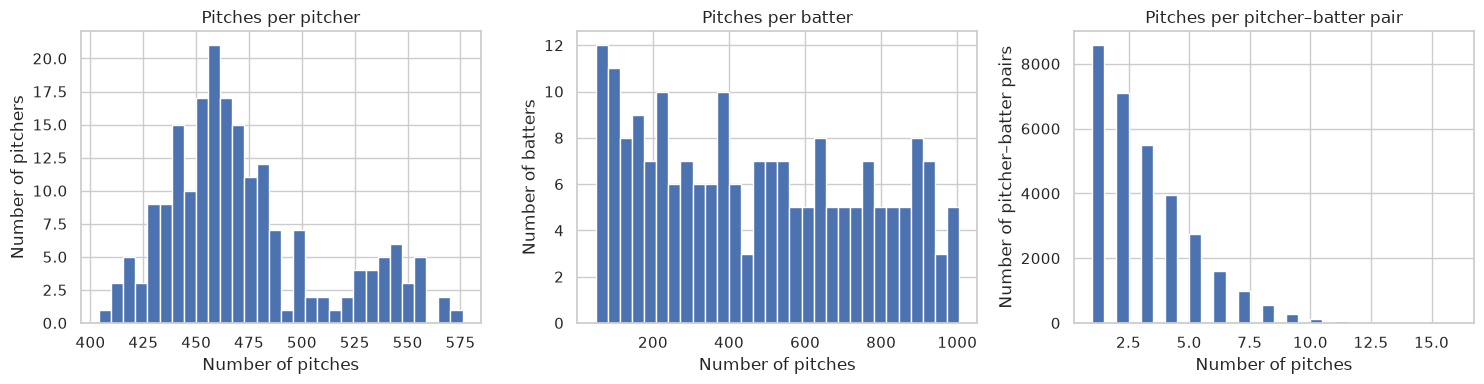

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, counts, label in zip(
    axes,
    [pitcher_counts, batter_counts, pair_counts],
    ["pitcher", "batter", "pitcher–batter pair"],
):
    ax.hist(counts, bins=30, edgecolor="white")
    ax.set_title(f"Pitches per {label}")
    ax.set_xlabel("Number of pitches")
    ax.set_ylabel(f"Number of {label}s")

fig.tight_layout()
plt.show()

So far, all the data looks reasonable and as expected, with one exception: contact rates appear to be more extreme than expected based on platoon matchups (in both directions). Same-side matchups have considerably lower contact rates than I'd expect (despite the fact that they're same-side matchups and therefore favor the pitcher), and opposite-side matchups have considerably higher contract rates than I'd expect (also despite the fact that they're opposite-side matchups and therefore favor the batter). Since this is the data provided for this project, I'll treat it as ground truth, but this is something I'll want to keep flagged mentally as I evaluate the model I eventually build within the context of baseball models I've typically seen/built before.